# Assignment 4 — One- and Two-Sample Tests

**Course:** STA1

**Group members:** Bibek Paudel, Dora Buruncuk, Supendra Bogati

## Table of contents
1. [Part 1 — One-sample decisions](#part1)
2. [Part 2 — Independent coating processes](#part2)
3. [Part 3 — Paired building-energy measurements](#part3)
4. [Part 4 — Comparing two independent proportions](#part4)
5. [Part 5 — AI-use and conclusion](#part5)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t, ttest_ind, shapiro, probplot, skew

DATA = "data/"

coating = pd.read_csv(DATA + "assignment04_coating_durability.csv")   # Part 2

print(f"coating: {coating.shape[0]} rows x {coating.shape[1]} columns")

coating: 92 rows x 3 columns


<a id="part2"></a>
# Part 2 — Independent coating processes

> The file assignment04_coating_durability.csv contains independent specimens from a standard
> and modified coating process. Let
> $$\delta = \mu_{\text{modified}} - \mu_{\text{standard}},$$
> measured in durability hours. An increase of at least 8 hours is considered practically
> important.

**Population:** all coated specimens that could be produced by each process.

**Parameter:** $\delta = \mu_{\text{modified}} - \mu_{\text{standard}}$, the difference in mean
durability in hours. A positive $\delta$ means the modified process lasts longer on average than
the standard process.

**Observational unit:** one coated specimen.

**Design:** two independent groups, standard and modified, since each specimen is coated by only
one process.

**Assumptions:** the specimens are representative of each process, the two groups are independent
of each other and within themselves, and the values in each group are close to normal, or each
$n$ is large enough for the sample mean to be, so that a $t$ procedure is reasonable.

## a)

> Explain why the samples are independent rather than paired. Report group $n$, mean, sample
> standard deviation, and boxplots.

**Why independent, not paired:** Each specimen is coated by exactly one process, standard or
modified, so no specimen in one group has a specific and meaningful partner in the other
(Definition 8.2). Knowing which specimens are in the standard group says nothing about the
values in the modified group, so the two samples are independent (Definition 8.1).

           n    mean      s
standard  44  117.29  15.75
modified  48  132.49  22.19


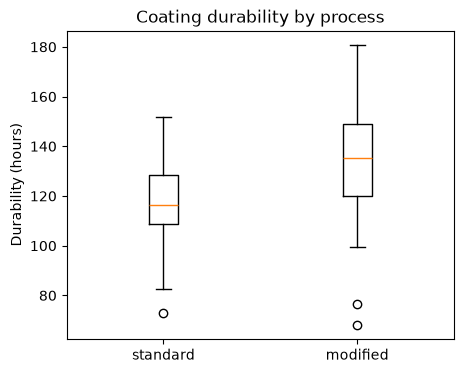

In [2]:
standard = coating.loc[coating["process"] == "standard", "durability_h"].to_numpy()
modified = coating.loc[coating["process"] == "modified", "durability_h"].to_numpy()

n1, n2 = len(standard), len(modified)
x1, x2 = standard.mean(), modified.mean()
s1, s2 = standard.std(ddof=1), modified.std(ddof=1)

summary = pd.DataFrame({"n": [n1, n2], "mean": [x1, x2], "s": [s1, s2]},
                        index=["standard", "modified"])
print(summary.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([standard, modified])
ax.set_xticklabels(["standard", "modified"])
ax.set_ylabel("Durability (hours)")
ax.set_title("Coating durability by process")
plt.show()

**Group summary:** modified specimens lasted longer on average (132.49 vs 117.29 hours) and
showed more spread ($s=22.19$ vs $15.75$ hours). The boxplot shows the modified group's box and
median sitting higher than the standard group's.

## b)

> State two-sided hypotheses about $\delta$. Use Welch's two-sample $t$ procedure and report the
> estimated difference, 95% confidence interval, statistic, approximate degrees of freedom, and
> $p$-value. Do not use a preliminary variance test to switch automatically between pooled and
> Welch procedures.

$$H_0: \delta = 0 \qquad H_1: \delta \ne 0 \qquad \alpha = 0.05$$

The classical pooled test needs equal population variances. Welch's test does not, so there is no
need to test for equal variances first.

Let $1=$ standard and $2=$ modified:

$$\hat\delta = \bar x_2 - \bar x_1, \qquad \text{SE} = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}$$

$$t_{\text{obs}} = \frac{\hat\delta - 0}{\text{SE}}, \qquad
\nu = \frac{\left(\frac{s_1^2}{n_1}+\frac{s_2^2}{n_2}\right)^2}
{\frac{(s_1^2/n_1)^2}{n_1-1}+\frac{(s_2^2/n_2)^2}{n_2-1}}
\qquad \text{(Theorem 8.1)}$$

In [3]:
alpha = 0.05

diff = x2 - x1   # modified - standard = delta_hat
se = np.sqrt(s1**2 / n1 + s2**2 / n2)

nu = (s1**2 / n1 + s2**2 / n2)**2 / ((s1**2/n1)**2/(n1-1) + (s2**2/n2)**2/(n2-1))

t_crit = t.ppf(0.975, nu)
moe = t_crit * se
ci_lo, ci_hi = diff - moe, diff + moe

t_obs = diff / se
p_two = 2 * t.sf(abs(t_obs), nu)

res = ttest_ind(modified, standard, equal_var=False)   # check with SciPy

print(f"delta_hat = {x2:.2f} - {x1:.2f} = {diff:.2f} hours")
print(f"SE = {se:.4f}")
print(f"df (Welch) = {nu:.2f}")
print(f"t_0.975 = {t_crit:.4f}")
print(f"95% CI = [{ci_lo:.2f}, {ci_hi:.2f}] hours")
print(f"t = {t_obs:.3f}")
print(f"two-sided p = {p_two:.4f}")
print(f"SciPy check: t = {res.statistic:.3f}, df = {res.df:.2f}, p = {res.pvalue:.4f}")
print(f"decision at alpha = {alpha}:", "reject H0" if p_two < alpha else "fail to reject H0")

delta_hat = 132.49 - 117.29 = 15.20 hours
SE = 3.9867
df (Welch) = 84.84
t_0.975 = 1.9883
95% CI = [7.27, 23.13] hours
t = 3.812
two-sided p = 0.0003
SciPy check: t = 3.812, df = 84.84, p = 0.0003
decision at alpha = 0.05: reject H0


**Result:** modified specimens last an estimated 15.20 hours longer on average than standard
($\hat\delta=15.20$), 95 % CI $[7.27,\ 23.13]$ hours, $t=3.812$ on $\nu=84.84$ df, two-sided
$p=0.0003$.

**Decision:** $p=0.0003<0.05$, so we reject $H_0$.

**Conclusion:** the data give evidence that the modified process has a higher mean durability
than the standard process.

## c)

> Assess independence from the design and distribution shape and unusual observations from group
> plots or residual diagnostics. State what the plots cannot establish.

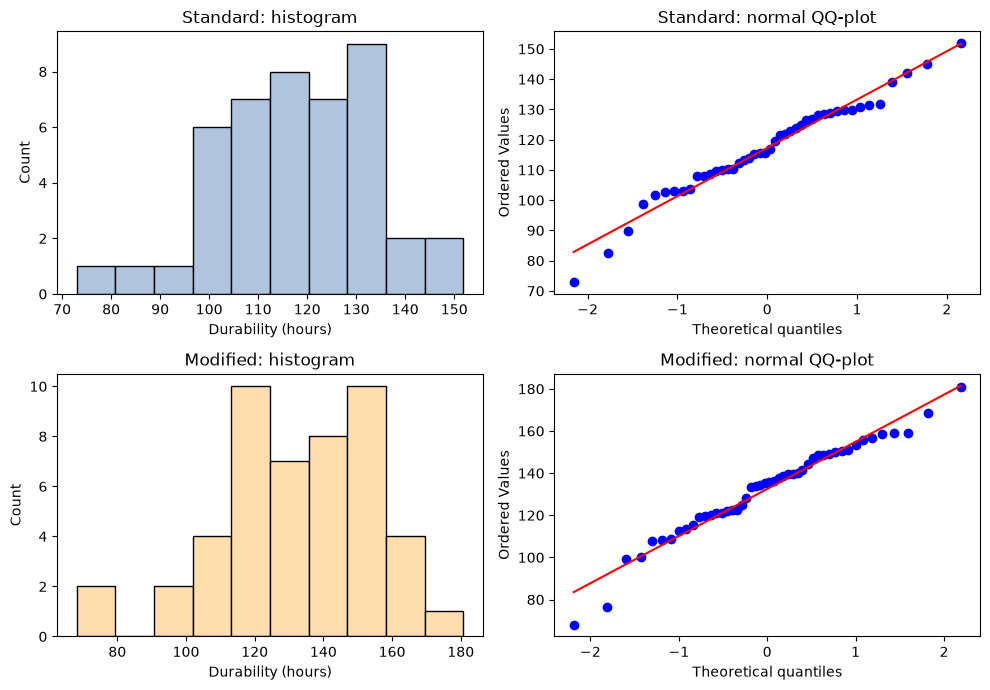

Shapiro–Wilk standard: W = 0.977, p = 0.523
Shapiro–Wilk modified: W = 0.970, p = 0.247
skewness standard: -0.39
skewness modified: -0.59
standard outliers (1.5xIQR rule): [72.93]
modified outliers (1.5xIQR rule): [76.48 68.12]


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].hist(standard, bins=10, color="lightsteelblue", edgecolor="black")
axes[0, 0].set(title="Standard: histogram", xlabel="Durability (hours)", ylabel="Count")
probplot(standard, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Standard: normal QQ-plot")

axes[1, 0].hist(modified, bins=10, color="navajowhite", edgecolor="black")
axes[1, 0].set(title="Modified: histogram", xlabel="Durability (hours)", ylabel="Count")
probplot(modified, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Modified: normal QQ-plot")

fig.tight_layout()
plt.show()

W1, p1 = shapiro(standard)
W2, p2 = shapiro(modified)
print(f"Shapiro–Wilk standard: W = {W1:.3f}, p = {p1:.3f}")
print(f"Shapiro–Wilk modified: W = {W2:.3f}, p = {p2:.3f}")
print(f"skewness standard: {skew(standard):.2f}")
print(f"skewness modified: {skew(modified):.2f}")

def iqr_outliers(x):
    q1, q3 = np.percentile(x, 25), np.percentile(x, 75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return x[(x < lo) | (x > hi)]

print(f"standard outliers (1.5xIQR rule): {iqr_outliers(standard)}")
print(f"modified outliers (1.5xIQR rule): {iqr_outliers(modified)}")

**Independence from the design:** each specimen was coated by only one process, so the two
groups are independent of each other, as in a) (Definition 8.1), not paired (Definition 8.2).
Independence within each group is not shown by this alone: if specimens from the same batch or
test rig share conditions, their durability values could be correlated, and neither the design
nor the plots below can rule that out.

**Distribution shape:** both histograms are roughly symmetric and single-peaked. The QQ-plots
follow the line through most of each sample, but the lowest point in each group falls below it,
and both samples are slightly left-skewed (standard: $-0.39$; modified: $-0.59$). Shapiro–Wilk
gives no evidence against normality for either group (standard: $p=0.523$; modified: $p=0.247$),
so with $n=44$ and $n=48$ the Welch $t$ procedure in b) is still reasonable.

**Unusual observations:** the boxplot in a) flags one low point in the standard group (72.93 h)
and two low points in the modified group (68.12 h and 76.48 h) as 1.5×IQR outliers. None looks
impossible for a durability measurement, and removing them is not justified without independent
evidence of a measurement problem.

**What the plots cannot establish:** histograms, QQ-plots and boxplots describe only the shape of
the values collected. They cannot confirm that the specimens are independent or representative,
since that depends on how they were produced and selected, not on the data's distribution. They
also cannot prove normality, only fail to contradict it, and they say nothing about whether the
coating process itself caused the difference between the groups.

## d)

> Compare the interval with both zero and the 8-hour practical threshold. Give a recommendation
> that reflects statistical uncertainty and practical importance.

In [5]:
print(f"95% CI = [{ci_lo:.2f}, {ci_hi:.2f}] hours")
print("0 inside the interval:", ci_lo <= 0 <= ci_hi)
print("8 inside the interval:", ci_lo <= 8 <= ci_hi)

95% CI = [7.27, 23.13] hours
0 inside the interval: False
8 inside the interval: True


**Versus zero:** the interval $[7.27,\ 23.13]$ hours lies entirely above 0, consistent with
rejecting $H_0$ in b): the data support a real difference between the two processes.

**Versus the 8-hour threshold:** the interval still straddles 8 hours. Values as low as 7.27
hours (below the practical threshold) and as high as 23.13 hours (well above it) are both
compatible with the data.

**Recommendation:** statistical significance and practical importance answer different
questions. The point estimate, 15.20 hours, is almost twice the 8-hour threshold, so the best
guess favours switching to the modified process. But the interval's lower end, 7.27 hours, falls
short of 8 hours, so the data cannot yet rule out an improvement too small to matter. More
specimens would narrow the interval and settle this.